# Logistic Regression and k-NN comparison

The split, five folds, MI ranking, preprocessing, and metrics match notebook 03.
AP selects feature counts and parameters. Final refits use all 172,459 training
rows. The held-out test set is evaluated once per selected model.

Run from the repository root or `notebooks/` after installing `requirements.txt`.
In Colab, clone/upload the repository, install its requirements, and change the
working directory to the repository root before running these cells.
CSV outputs are saved in `results/`. No class weights or log transform are used.
Notebook 02 reports LR AP 0.6048 without weighting and 0.5975 with balanced weights.

## 1. Imports, data, and shared split

In [1]:
from pathlib import Path
import sys
import time
import json
import platform
import warnings

experiment_started = time.perf_counter()
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
get_ipython().run_line_magic("matplotlib", "inline")
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score,
    average_precision_score, confusion_matrix, f1_score, precision_score,
    recall_score, roc_auc_score,
)
from sklearn.model_selection import ParameterGrid, StratifiedKFold, train_test_split
from sklearn.preprocessing import OrdinalEncoder
from threadpoolctl import threadpool_limits

# Limit native thread pools to one thread; k-NN also uses n_jobs=1.
thread_limit = threadpool_limits(limits=1)
cwd = Path.cwd()
repo_root = cwd if (cwd / "src" / "preprocessing.py").exists() else cwd.parent
assert (repo_root / "src" / "preprocessing.py").exists(), (
    "Open this notebook from the project root or notebooks/ directory."
)
sys.path.insert(0, str(repo_root / "src"))
from preprocessing import NUMERIC_COLUMNS, build_preprocessor, prepare_xy, select_features

results_dir = repo_root / "results"
results_dir.mkdir(exist_ok=True)
data_path = repo_root / "data" / "processed" / "census_income_adults.csv"
if not data_path.exists():
    import subprocess
    subprocess.run([sys.executable, "src/data_loader.py"], cwd=repo_root, check=True)
df = pd.read_csv(data_path, skipinitialspace=True)
X, y = prepare_xy(df)
X = select_features(X, include_migration=False)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
X_dev, _, y_dev, _ = train_test_split(
    X_train, y_train, train_size=30_000, stratify=y_train, random_state=42
)
folds = list(StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
).split(X_dev, y_dev))
FEATURE_COUNTS = [5, 10, 15, 17, 20, 25, 33]
MODEL_NAMES = ["Logistic Regression", "k-NN"]
print(f"Python {platform.python_version()}; sklearn {sklearn.__version__}; pandas {pd.__version__}")
print(f"Original features: {X.shape[1]}")
print(f"Training rows: {len(X_train):,}; held-out test rows: {len(X_test):,}")
print(f"CV sample rows: {len(X_dev):,}; positive rate: {y_dev.mean():.4f}")
print(f"CV folds: {len(folds)}; feature counts: {FEATURE_COUNTS}")

Python 3.13.3; sklearn 1.9.1; pandas 3.1.1
Original features: 33
Training rows: 172,459; held-out test rows: 43,115
CV sample rows: 30,000; positive rate: 0.0861
CV folds: 5; feature counts: [5, 10, 15, 17, 20, 25, 33]


## 2. MI ranking within each training fold

In [2]:
def rank_features_by_mi(X_fit, y_fit):
    # Rank original features using only this fold's training rows.
    work = X_fit.copy()
    numeric = [column for column in NUMERIC_COLUMNS if column in work.columns]
    categorical = [column for column in work.columns if column not in numeric]

    if numeric:
        work[numeric] = SimpleImputer(strategy="median").fit_transform(work[numeric])
    if categorical:
        encoded = SimpleImputer(
            strategy="constant", fill_value="Missing"
        ).fit_transform(work[categorical])
        encoded = OrdinalEncoder(
            handle_unknown="use_encoded_value", unknown_value=-1
        ).fit_transform(encoded)
        work[categorical] = encoded

    discrete = [column in categorical for column in work.columns]
    scores = mutual_info_classif(
        work, y_fit, discrete_features=discrete,
        random_state=42, n_neighbors=3,
    )
    return (
        pd.DataFrame({"feature": work.columns, "MI": scores})
        .sort_values(["MI", "feature"], ascending=[False, True])
        .reset_index(drop=True)
    )

## 3. Evaluation functions and initial model comparison

Models use sklearn defaults, with `random_state=42` for LR and `n_jobs=1` for k-NN.
Native thread pools are limited to one thread. LR uses `max_iter=100`.
For `C=10`, fitting starts at `max_iter=200` because 100 did not converge
in the earlier k=33 run. If convergence fails, the iteration limit is doubled
and the model is refit, up to 25,600. Attempts are recorded; fit time includes retries.
No test scores control iteration limits.
Prediction time measures `predict_proba`; preprocessing time includes both transforms.

In [3]:
warning_rows = []
fit_attempt_rows = []

def save_records():
    pd.DataFrame(warning_rows, columns=["context", "category", "message", "max_iter"]).to_csv(
        results_dir / "lr_knn_warnings.csv", index=False
    )
    pd.DataFrame(fit_attempt_rows).to_csv(results_dir / "lr_knn_fit_attempts.csv", index=False)

def make_model(model_name, params=None):
    settings = {} if params is None else dict(params)
    if model_name == "Logistic Regression":
        if settings.get("C", 1.0) == 10:
            settings.setdefault("max_iter", 200)
        return LogisticRegression(random_state=42, **settings)
    if model_name == "k-NN":
        return KNeighborsClassifier(n_jobs=1, **settings)
    raise ValueError(f"Unknown model: {model_name}")

def fit_model(model_name, params, Z_fit, y_fit, context):
    model = make_model(model_name, params)
    started = time.perf_counter()
    while True:
        attempt_started = time.perf_counter()
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            model.fit(Z_fit, y_fit)
        attempt_seconds = time.perf_counter() - attempt_started
        limit = model.get_params().get("max_iter")
        convergence = any(issubclass(w.category, ConvergenceWarning) for w in caught)
        fit_attempt_rows.append({"context": context, "model": model_name,
                                 "max_iter": limit, "seconds": attempt_seconds,
                                 "convergence_warning": convergence})
        for warning in caught:
            warning_rows.append({"context": context, "category": warning.category.__name__,
                                 "message": str(warning.message), "max_iter": limit})
            print(f"{context}: {warning.category.__name__}, max_iter={limit}: {warning.message}", flush=True)
        if not convergence:
            break
        if model_name != "Logistic Regression" or limit >= 25_600:
            save_records()
            raise RuntimeError(f"Unresolved convergence warning: {context}")
        settings = dict(params or {})
        settings["max_iter"] = limit * 2
        print(f"Retrying {context} with max_iter={settings['max_iter']}", flush=True)
        model = make_model(model_name, settings)
    return model, time.perf_counter() - started

def metrics(y_true, probability):
    predicted = (probability >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, predicted, labels=[0, 1]).ravel()
    return {
        "AP": average_precision_score(y_true, probability),
        "ROC_AUC": roc_auc_score(y_true, probability),
        "Accuracy": accuracy_score(y_true, predicted),
        "Precision": precision_score(y_true, predicted, zero_division=0),
        "Recall": recall_score(y_true, predicted, zero_division=0),
        "F1": f1_score(y_true, predicted, zero_division=0),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    }

def run_cv(model_name, k, params=None, stage="initial"):
    rows = []
    for fold_number, (train_idx, valid_idx) in enumerate(folds, start=1):
        X_fit, y_fit = X_dev.iloc[train_idx], y_dev.iloc[train_idx]
        X_valid, y_valid = X_dev.iloc[valid_idx], y_dev.iloc[valid_idx]
        mi_seconds = 0.0
        if k == X_dev.shape[1]:
            selected = list(X_fit.columns)
        else:
            started = time.perf_counter()
            ranking = rank_features_by_mi(X_fit, y_fit)
            selected = ranking["feature"].head(k).tolist()
            mi_seconds = time.perf_counter() - started
        X_fit_k, X_valid_k = X_fit[selected], X_valid[selected]
        preprocessor = build_preprocessor(X_fit_k, log_money=False)
        started = time.perf_counter()
        Z_fit = preprocessor.fit_transform(X_fit_k)
        Z_valid = preprocessor.transform(X_valid_k)
        preprocessing_seconds = time.perf_counter() - started
        context = f"{stage}/{model_name}/k={k}/fold={fold_number}/params={params}"
        model, fit_seconds = fit_model(model_name, params, Z_fit, y_fit, context)
        started = time.perf_counter()
        probability = model.predict_proba(Z_valid)[:, 1]
        predict_seconds = time.perf_counter() - started
        rows.append({
            "model": model_name, "k": k, "fold": fold_number,
            **metrics(y_valid, probability),
            "MI_seconds": mi_seconds, "preprocessing_seconds": preprocessing_seconds,
            "fit_seconds": fit_seconds, "predict_seconds": predict_seconds,
            "max_iter": model.get_params().get("max_iter"),
            "selected_features": json.dumps(selected),
        })
    save_records()
    return pd.DataFrame(rows)

all_folds = []
for model_name in MODEL_NAMES:
    for k in FEATURE_COUNTS:
        print(f"Running {model_name}, {k} features ...", flush=True)
        all_folds.append(run_cv(model_name, k))
        pd.concat(all_folds, ignore_index=True).to_csv(results_dir / "lr_knn_cv_folds.csv", index=False)
fold_results = pd.concat(all_folds, ignore_index=True)
summary = (
    fold_results.groupby(["model", "k"])
    .agg(
        AP_mean=("AP", "mean"), AP_sd=("AP", "std"),
        ROC_AUC_mean=("ROC_AUC", "mean"), Accuracy_mean=("Accuracy", "mean"),
        Precision_mean=("Precision", "mean"), Recall_mean=("Recall", "mean"),
        F1_mean=("F1", "mean"), MI_seconds_mean=("MI_seconds", "mean"),
        preprocessing_seconds_mean=("preprocessing_seconds", "mean"),
        fit_seconds_mean=("fit_seconds", "mean"), predict_seconds_mean=("predict_seconds", "mean"),
    ).reset_index()
)
summary.to_csv(results_dir / "lr_knn_cv_summary.csv", index=False)
display(summary.round(4))

Running Logistic Regression, 5 features ...


Running Logistic Regression, 10 features ...


Running Logistic Regression, 15 features ...


Running Logistic Regression, 17 features ...


Running Logistic Regression, 20 features ...


Running Logistic Regression, 25 features ...


... (5 outputs left out)

Running k-NN, 20 features ...


Running k-NN, 25 features ...


Running k-NN, 33 features ...


,model,k,AP_mean,AP_sd,ROC_AUC_mean,Accuracy_mean,Precision_mean,Recall_mean,F1_mean,MI_seconds_mean,preprocessing_seconds_mean,fit_seconds_mean,predict_seconds_mean
0,Logistic Regression,5,0.4821,0.0274,0.8791,0.9243,0.6481,0.2647,0.3754,0.4735,0.0268,0.0147,0.0002
1,Logistic Regression,10,0.5654,0.0134,0.9072,0.9291,0.6865,0.3259,0.4414,0.4772,0.0501,0.0223,0.0002
2,Logistic Regression,15,0.5984,0.0101,0.9186,0.9327,0.7017,0.3797,0.4925,0.4404,0.0554,0.0381,0.0002
3,Logistic Regression,17,0.6062,0.0090,0.9205,0.9335,0.7076,0.3889,0.5017,0.4294,0.0548,0.0395,0.0002
4,Logistic Regression,20,0.6045,0.0079,0.9201,0.9341,0.7131,0.3924,0.5060,0.4310,0.0668,0.0522,0.0002
5,Logistic Regression,25,0.6044,0.0083,0.9196,0.9338,0.7087,0.3924,0.5050,0.4622,0.0810,0.0745,0.0003
6,Logistic Regression,33,0.6047,0.0084,0.9198,0.9337,0.7062,0.3944,0.5060,0.0000,0.1482,0.0924,0.0003
7,k-NN,5,0.3309,0.0378,0.7778,0.9175,0.5420,0.2864,0.3744,0.4620,0.0235,0.0009,1.8079
8,k-NN,10,0.4061,0.0163,0.8108,0.9217,0.5749,0.3475,0.4330,0.4223,0.0365,0.0014,1.8482
9,k-NN,15,0.4314,0.0158,0.8270,0.9242,0.5959,0.3777,0.4621,0.4247,0.0528,0.0014,1.8750


## 4. Compare AP and computation time

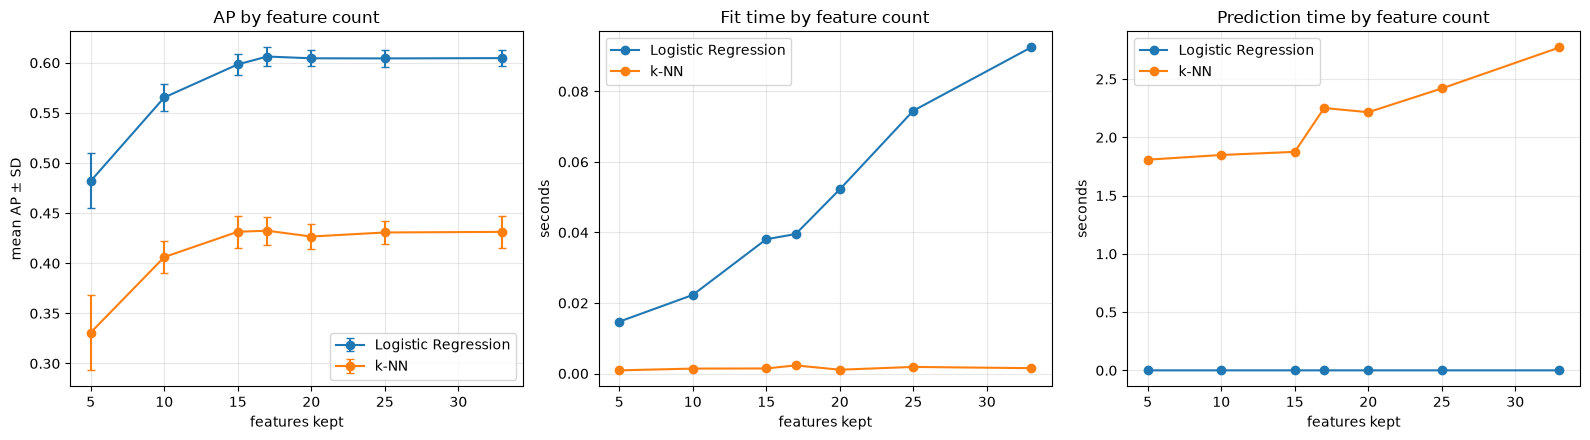

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for model_name, group in summary.groupby("model"):
    group = group.sort_values("k")
    axes[0].errorbar(group["k"], group["AP_mean"], yerr=group["AP_sd"],
                     marker="o", capsize=3, label=model_name)
    axes[1].plot(group["k"], group["fit_seconds_mean"], marker="o", label=model_name)
    axes[2].plot(group["k"], group["predict_seconds_mean"], marker="o", label=model_name)
axes[0].set(title="AP by feature count", xlabel="features kept", ylabel="mean AP ± SD")
axes[1].set(title="Fit time by feature count", xlabel="features kept", ylabel="seconds")
axes[2].set(title="Prediction time by feature count", xlabel="features kept", ylabel="seconds")
for ax in axes:
    ax.legend()
    ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

## 5. Hyperparameter search

Each model keeps the feature count selected by initial CV AP (smaller k breaks ties).
ParameterGrid enumerates settings on the same five folds. The first tested setting
wins an AP tie. The comparison table uses CV results at the selected k.

In [5]:
chosen_k = (
    summary.sort_values(["model", "AP_mean", "k"], ascending=[True, False, True])
    .groupby("model", as_index=False).first()[["model", "k"]]
    .set_index("model")["k"].astype(int).to_dict()
)
print("Feature count chosen from initial CV AP:", chosen_k)
parameter_grids = {
    "Logistic Regression": {"C": [0.01, 0.1, 1, 10]},
    "k-NN": {"n_neighbors": [5, 15, 31, 51, 71, 101, 151], "weights": ["uniform", "distance"]},
}
display(pd.DataFrame([
    {"model": name, "parameter": key, "search_range": values}
    for name, grid in parameter_grids.items() for key, values in grid.items()
]))
tuning_rows, tuning_folds = [], []
for model_name, grid in parameter_grids.items():
    for candidate, params in enumerate(ParameterGrid(grid)):
        print(f"Tuning {model_name}, k={chosen_k[model_name]}: {params}", flush=True)
        scores = run_cv(model_name, chosen_k[model_name], params, stage="tuning")
        tuning_folds.append(scores.assign(candidate=candidate, params=json.dumps(params)))
        tuning_rows.append({
            "model": model_name, "k": chosen_k[model_name], "candidate": candidate,
            "params": params, "AP_mean": scores["AP"].mean(), "AP_sd": scores["AP"].std(),
            **{f"{metric}_mean": scores[metric].mean() for metric in [
                "ROC_AUC", "Accuracy", "Precision", "Recall", "F1", "MI_seconds",
                "preprocessing_seconds", "fit_seconds", "predict_seconds"]},
        })
        pd.DataFrame(tuning_rows).assign(
            params=lambda frame: frame["params"].map(json.dumps)
        ).to_csv(results_dir / "lr_knn_tuning.csv", index=False)
        pd.concat(tuning_folds, ignore_index=True).to_csv(
            results_dir / "lr_knn_tuning_folds.csv", index=False
        )
tuning_summary = pd.DataFrame(tuning_rows)
best_tuning = (
    tuning_summary.sort_values(["model", "AP_mean"], ascending=[True, False])
    .groupby("model", as_index=False).first()
)
display(tuning_summary.round(4))
display(best_tuning[["model", "k", "params", "AP_mean", "AP_sd"]])
knn_best = best_tuning.loc[best_tuning["model"] == "k-NN", "params"].iloc[0]
knn_at_upper_bound = knn_best["n_neighbors"] == max(parameter_grids["k-NN"]["n_neighbors"])
print(f"Best k-NN n_neighbors: {knn_best['n_neighbors']}; at upper bound: {knn_at_upper_bound}")
initial_chosen = summary[summary.apply(lambda row: row["k"] == chosen_k[row["model"]], axis=1)]
comparison_columns = ["model", "k", "setting", "AP_mean", "ROC_AUC_mean", "F1_mean",
                      "fit_seconds_mean", "predict_seconds_mean"]
comparison = pd.concat([initial_chosen.assign(setting="initial"),
                        best_tuning.assign(setting="best")], ignore_index=True)[comparison_columns]
display(comparison.round(4))
comparison.to_csv(results_dir / "lr_knn_initial_vs_best.csv", index=False)

Feature count chosen from initial CV AP: {'Logistic Regression': 17, 'k-NN': 17}


,model,parameter,search_range
0,Logistic Regression,C,"[0.01, 0.1, 1, 10]"
1,k-NN,n_neighbors,"[5, 15, 31, 51, 71, 101, 151]"
2,k-NN,weights,"[uniform, distance]"


Tuning Logistic Regression, k=17: {'C': 0.01}


Tuning Logistic Regression, k=17: {'C': 0.1}


Tuning Logistic Regression, k=17: {'C': 1}


Tuning Logistic Regression, k=17: {'C': 10}


... (14 outputs left out)

,model,k,candidate,params,AP_mean,AP_sd,ROC_AUC_mean,Accuracy_mean,Precision_mean,Recall_mean,F1_mean,MI_seconds_mean,preprocessing_seconds_mean,fit_seconds_mean,predict_seconds_mean
0,Logistic Regression,17,0,{'C': 0.01},0.5876,0.0122,0.9143,0.9301,0.7741,0.2666,0.3963,0.4464,0.0558,0.0183,0.0002
1,Logistic Regression,17,1,{'C': 0.1},0.6073,0.0102,0.9203,0.9336,0.7249,0.3688,0.4886,0.4442,0.0578,0.0377,0.0002
2,Logistic Regression,17,2,{'C': 1},0.6062,0.0090,0.9205,0.9335,0.7076,0.3889,0.5017,0.4335,0.0554,0.0399,0.0004
3,Logistic Regression,17,3,{'C': 10},0.6045,0.0087,0.9198,0.9335,0.7052,0.3920,0.5037,0.4245,0.0573,0.0459,0.0002
4,k-NN,17,0,"{'n_neighbors': 5, 'weights': 'uniform'}",0.4325,0.0138,0.8260,0.9239,0.5907,0.3824,0.4639,0.4589,0.0586,0.0012,2.2268
5,k-NN,17,1,"{'n_neighbors': 5, 'weights': 'distance'}",0.4589,0.0158,0.8256,0.9216,0.5637,0.3990,0.4671,0.4619,0.0584,0.0010,2.0538
6,k-NN,17,2,"{'n_neighbors': 15, 'weights': 'uniform'}",0.5206,0.0054,0.8782,0.9291,0.6785,0.3375,0.4507,0.4329,0.0546,0.0028,2.0457
7,k-NN,17,3,"{'n_neighbors': 15, 'weights': 'distance'}",0.5287,0.0120,0.8766,0.9279,0.6496,0.3553,0.4592,0.4142,0.0541,0.0011,1.8525
8,k-NN,17,4,"{'n_neighbors': 31, 'weights': 'uniform'}",0.5495,0.0063,0.8965,0.9305,0.7316,0.3057,0.4306,0.4271,0.0608,0.0026,1.9421
9,k-NN,17,5,"{'n_neighbors': 31, 'weights': 'distance'}",0.5460,0.0096,0.8945,0.9300,0.7021,0.3259,0.4449,0.4213,0.0562,0.0011,1.9358


,model,k,params,AP_mean,AP_sd
0,Logistic Regression,17,{'C': 0.1},0.607257,0.010206
1,k-NN,17,"{'n_neighbors': 51, 'weights': 'uniform'}",0.554755,0.010298


Best k-NN n_neighbors: 51; at upper bound: False


,model,k,setting,AP_mean,ROC_AUC_mean,F1_mean,fit_seconds_mean,predict_seconds_mean
0,Logistic Regression,17,initial,0.6062,0.9205,0.5017,0.0395,0.0002
1,k-NN,17,initial,0.4325,0.8260,0.4639,0.0023,2.2515
2,Logistic Regression,17,best,0.6073,0.9203,0.4886,0.0377,0.0002
3,k-NN,17,best,0.5548,0.9011,0.4079,0.0009,1.9392


## 6. One-time held-out test evaluation

Each selected model is refit on all 172,459 training rows. MI uses these training
rows only and is skipped for k=33. Test scores do not change any settings.
Prediction progress is checkpointed before evaluation. An interrupted prediction
is recorded without assigning a test score.

In [6]:
assert len(X_train) == 172_459
final_rows, final_predictions, final_models = [], {}, {}
for _, choice in best_tuning.iterrows():
    model_name, k, params = choice["model"], int(choice["k"]), choice["params"]
    print(f"Final refit: {model_name}, k={k}, params={params}, rows={len(X_train)}", flush=True)
    mi_seconds = 0.0
    if k == X_train.shape[1]:
        selected = list(X_train.columns)
    else:
        started = time.perf_counter()
        ranking = rank_features_by_mi(X_train, y_train)
        selected = ranking["feature"].head(k).tolist()
        mi_seconds = time.perf_counter() - started
        ranking.to_csv(results_dir / ("lr_final_mi.csv" if model_name == "Logistic Regression"
                                     else "knn_final_mi.csv"), index=False)
    X_train_k, X_test_k = X_train[selected], X_test[selected]
    preprocessor = build_preprocessor(X_train_k, log_money=False)
    started = time.perf_counter()
    Z_train = preprocessor.fit_transform(X_train_k)
    Z_test = preprocessor.transform(X_test_k)
    preprocessing_seconds = time.perf_counter() - started
    model, fit_seconds = fit_model(model_name, params, Z_train, y_train, f"final/{model_name}")
    row = {"model": model_name, "k": k, "params": json.dumps(params),
           "train_rows": len(X_train), "test_rows": len(X_test),
           "MI_seconds": mi_seconds, "preprocessing_seconds": preprocessing_seconds,
           "fit_seconds": fit_seconds, "max_iter": model.get_params().get("max_iter"),
           "selected_features": json.dumps(selected), "status": "predicting"}
    final_rows.append(row)
    pd.DataFrame(final_rows).to_csv(results_dir / "lr_knn_test_results.csv", index=False)
    print(f"Predicting {len(X_test):,} test rows with {model_name} ...", flush=True)
    started = time.perf_counter()
    try:
        probability = model.predict_proba(Z_test)[:, 1]
    except (KeyboardInterrupt, MemoryError) as error:
        row.update(status=type(error).__name__, predict_seconds=time.perf_counter() - started)
        print(f"Prediction incomplete: {row}", flush=True)
        pd.DataFrame(final_rows).to_csv(results_dir / "lr_knn_test_results.csv", index=False)
        continue
    row.update(predict_seconds=time.perf_counter() - started, status="complete")
    row.update(metrics(y_test, probability))
    final_predictions[model_name] = (probability, (probability >= 0.5).astype(int))
    final_models[model_name] = (model, preprocessor, selected)
    pd.DataFrame(final_rows).to_csv(results_dir / "lr_knn_test_results.csv", index=False)
    save_records()
test_summary = pd.DataFrame(final_rows)
display(test_summary.drop(columns="selected_features").round(4))

Final refit: Logistic Regression, k=17, params={'C': 0.1}, rows=172459


Predicting 43,115 test rows with Logistic Regression ...


Final refit: k-NN, k=17, params={'n_neighbors': 51, 'weights': 'uniform'}, rows=172459


Predicting 43,115 test rows with k-NN ...


,model,k,params,train_rows,test_rows,MI_seconds,preprocessing_seconds,fit_seconds,max_iter,status,...,AP,ROC_AUC,Accuracy,Precision,Recall,F1,TN,FP,FN,TP
0,Logistic Regression,17,"{""C"": 0.1}",172459,43115,3.6707,0.3689,0.210,100.0,complete,...,0.6215,0.9207,0.9360,0.7409,0.3951,0.5154,38889,513,2246,1467
1,k-NN,17,"{""n_neighbors"": 51, ""weights"": ""uniform""}",172459,43115,3.3292,0.3396,0.004,NaN,complete,...,0.6050,0.9147,0.9343,0.7513,0.3547,0.4819,38966,436,2396,1317


## 7. Confusion matrices and ROC curves

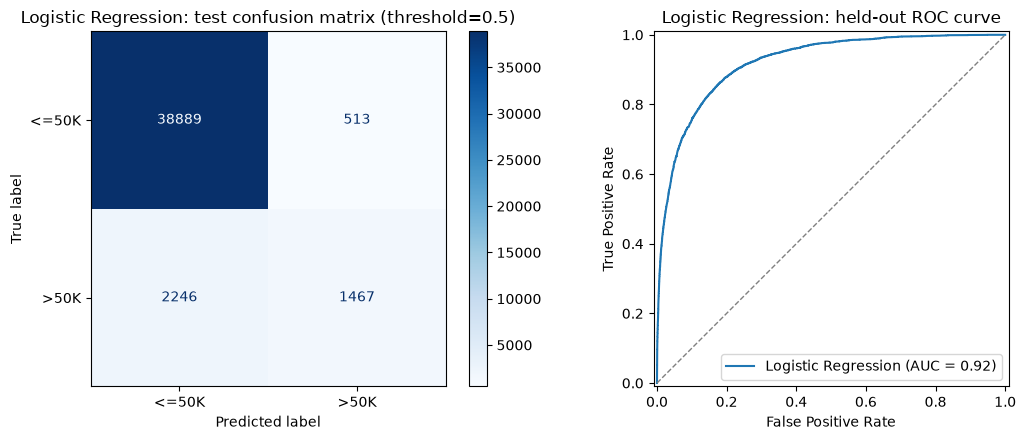

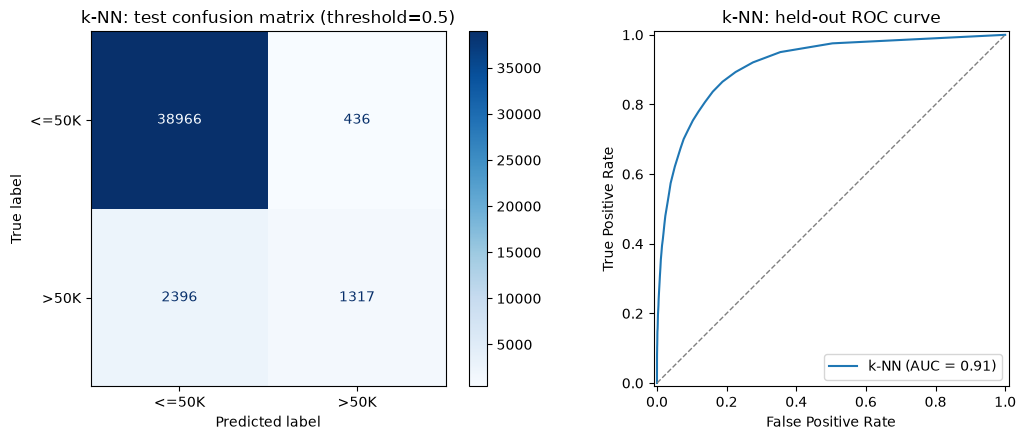

In [7]:
for model_name in MODEL_NAMES:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    if model_name not in final_predictions:
        for ax in axes:
            ax.text(0.5, 0.5, f"{model_name}: prediction incomplete", ha="center")
            ax.set_axis_off()
        plt.show()
        continue
    probability, predicted = final_predictions[model_name]
    ConfusionMatrixDisplay.from_predictions(
        y_test, predicted, labels=[0, 1], display_labels=["<=50K", ">50K"],
        cmap="Blues", values_format="d", ax=axes[0],
    )
    axes[0].set_title(f"{model_name}: test confusion matrix (threshold=0.5)")
    RocCurveDisplay.from_predictions(y_test, probability, name=model_name, ax=axes[1])
    axes[1].plot([0, 1], [0, 1], linestyle="--", color="grey", linewidth=1)
    axes[1].set_title(f"{model_name}: held-out ROC curve")
    axes[1].set_xlabel("False Positive Rate")
    axes[1].set_ylabel("True Positive Rate")
    fig.tight_layout()
    plt.show()

## 8. Final checks and execution record

In [8]:
assert len(X_dev) == 30_000
assert X.shape[1] == 33
assert len(folds) == 5
assert len(fold_results) == 70
assert fold_results.groupby(["model", "k"]).size().eq(5).all()
assert fold_results.loc[fold_results["k"] == 33, "MI_seconds"].eq(0).all()
assert len(tuning_summary) == 18
assert set(test_summary["model"]) == set(MODEL_NAMES)
save_records()
attempts = pd.DataFrame(fit_attempt_rows)
print("LR iteration limits used:", sorted(attempts["max_iter"].dropna().unique().astype(int)))
display(attempts.groupby(["model", "max_iter"], dropna=False).agg(
    attempts=("seconds", "size"), convergence_warnings=("convergence_warning", "sum")
).reset_index())
total_seconds = time.perf_counter() - experiment_started
execution_record = pd.DataFrame([{
    "total_seconds": total_seconds, "warnings": len(warning_rows),
    "python": platform.python_version(), "sklearn": sklearn.__version__,
    "pandas": pd.__version__, "numpy": np.__version__, "n_jobs": 1,
    "completed_test_models": int(test_summary["status"].eq("complete").sum()),
}])
execution_record.to_csv(results_dir / "lr_knn_execution.csv", index=False)
display(execution_record)
print("Final checks passed.")
print(f"Total execution time: {total_seconds:.2f} seconds")

LR iteration limits used: [np.int64(100), np.int64(200)]


,model,max_iter,attempts,convergence_warnings
0,Logistic Regression,100.0,51,0
1,Logistic Regression,200.0,5,0
2,k-NN,NaN,106,0


,total_seconds,warnings,python,sklearn,pandas,numpy,n_jobs,completed_test_models
0,409.454242,0,3.13.3,1.9.1,3.1.1,2.5.4,1,2


Final checks passed.
Total execution time: 409.45 seconds
